# 08 · What do selection and estimation each change?

This notebook fits no IRT model. It visualises saved per-model experiment records and,
when a frozen model adapter is available, the questions selected from its item pool.

- **Selection panels:** fix the estimator, compare random / anchors / information designs.
- **Estimator heatmap and parity plots:** fix the selector, compare accuracy / p-IRT / gp-IRT.
- **Item geometry:** show shared static designs versus model-specific adaptive questions.
- **Paired differences:** compare matching split, seed, budget and model targets.

The default `MODE="demo"` uses small synthetic 1D and 2D models with known parameters.
It demonstrates the mechanics, not evidence about MMLU. Set `MODE="results"` to read an actual
stage's `predictions.csv`; no training or full experiment is triggered in that mode.

In [1]:
import sys

sys.path.insert(0, "../scripts/irt")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from diagnostics import paired_comparison
from efficbench import ROOT
from protocol import calibrate_gp, evaluate

from cabench.design import parameter_context
from cabench.plotting import (
    plot_estimator_grid,
    plot_item_choices,
    plot_predictions,
    plot_score_errors,
)

MODE = "demo"  # "results" reads saved records without model fitting
RESULTS_DIR = ROOT / "results/irt/progression/voptimal"
N_DIMS = None  # Set explicitly when reading the multi-D sweep from notebook 06
K = 10
SEED = 0

# Optional in results mode: provide an adapter + aligned response rows for item geometry.
view_context = None
view_responses = None

## Load real results, or generate a small labelled demo

The demo holds model parameters fixed and calibrates gp-IRT using validation models only.
Three fixed model splits and three selection seeds give repeatable plots. The synthetic
latent parameters are known rather than learned: use results mode for research conclusions.

In [2]:
if MODE == "results":
    records = pd.read_csv(RESULTS_DIR / "predictions.csv")
    if N_DIMS is not None:
        records = records[records.n_dims == N_DIMS].copy()
    if records.n_dims.nunique() != 1:
        raise ValueError("Set N_DIMS to one dimension from the saved sweep")
    datasets = {"saved results": records}
    views = {} if view_context is None else {"saved results": (view_context, view_responses)}
    print(f"Loaded {len(records):,} predictions from {RESULTS_DIR}")
elif MODE == "demo":
    rng = np.random.default_rng(SEED)
    datasets, views = {}, {}
    for d in [1, 2]:
        theta = rng.normal(size=(100, d))
        alpha = rng.normal(0.8, 0.6, size=(160, d))
        beta = rng.normal(0, 1.3, size=160)
        item_ids = np.array([f"demo-item-{i}" for i in range(160)])
        population = parameter_context(theta[:60], alpha, beta, item_ids=item_ids)
        Y = rng.binomial(1, population["predict"](theta))
        splits, contexts = [], []
        for split_seed in range(3):
            order = np.random.default_rng(split_seed).permutation(len(Y))
            train, val, test = np.split(order, [60, 80])
            splits.append((train, val, test))
            contexts.append(parameter_context(theta[train], alpha, beta, item_ids=item_ids))
        criterion = "fisher" if d == 1 else "voptimal"
        selectors = ["random", "IRT anchors", f"{criterion}_static", f"{criterion}_adaptive"]
        methods = [(s, e) for s in selectors for e in ["accuracy", "p-IRT", "gp-IRT"]]
        calibrate_gp(
            Y, splits, contexts, selectors, ks=[5, 10, 20], seeds=range(3), item_ids=item_ids
        )
        _, records = evaluate(
            Y,
            splits,
            contexts,
            methods,
            ks=[5, 10, 20],
            seeds=range(3),
            solver="newton",
            return_records=True,
            item_ids=item_ids,
        )
        label = f"SYNTHETIC DEMO, D={d}"
        datasets[label] = records
        # Weakest and strongest demo models receive visibly different adaptive questions.
        extremes = np.array([np.argmin(Y.mean(1)), np.argmax(Y.mean(1))])
        views[label] = (contexts[0], Y[extremes])
else:
    raise ValueError("MODE must be demo or results")

split 0 done
split 1 done
split 2 done
split 0 done
split 1 done
split 2 done
split 0 done
split 1 done
split 2 done
split 0 done
split 1 done
split 2 done


## Fix the estimator; change selection

Each panel uses one estimator and the same budgets / splits. Error bars are standard deviation
across split means after averaging seeds within models. Repeated deterministic designs do not
add independent trials. Curve height measures score error; it is separate from the information
criterion used to choose items.

SYNTHETIC DEMO, D=1


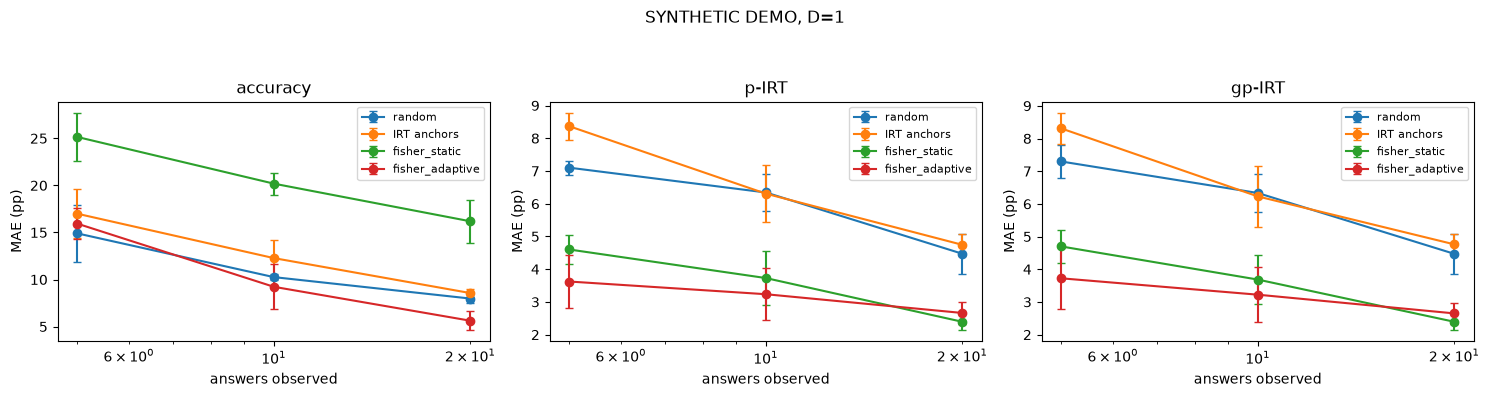

SYNTHETIC DEMO, D=2


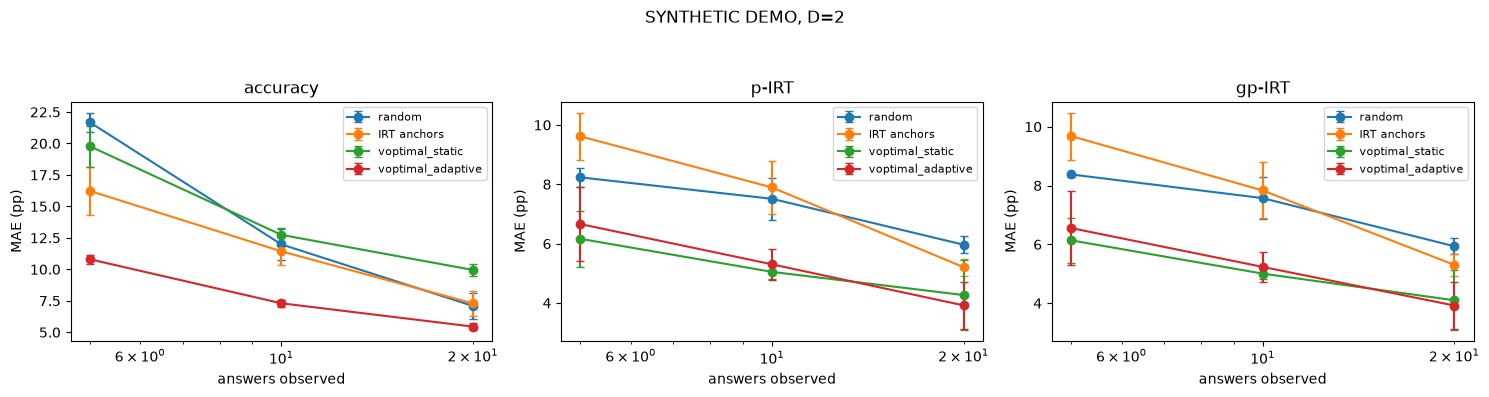

In [3]:
for label, records in datasets.items():
    print(label)
    fig = plot_score_errors(records)
    fig.suptitle(label)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()

## Fix the budget; separate selection from estimation

Rows change the selector. Columns change the estimator. Units are percentage points of
full-score MAE; lower is better. Deliberately informative items can bias raw accuracy,
so inspect p-IRT / gp-IRT instead of assuming every selector must improve every estimator.

SYNTHETIC DEMO, D=1


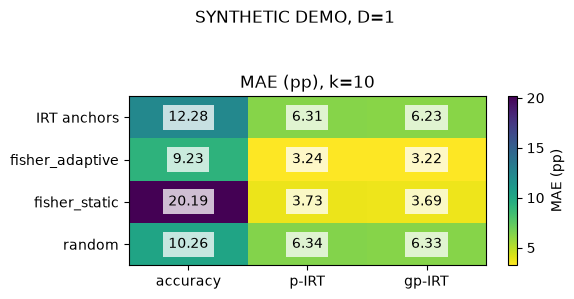

SYNTHETIC DEMO, D=2


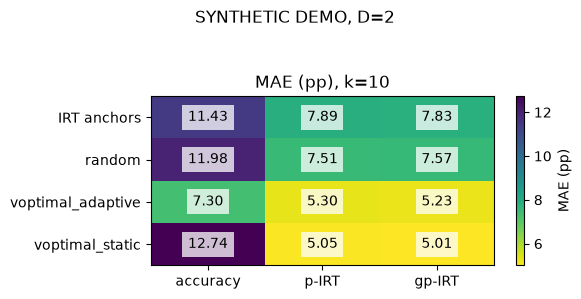

In [4]:
for label, records in datasets.items():
    if K not in set(records.k):
        raise ValueError(f"K={K} is unavailable; choose from {sorted(records.k.unique())}")
    print(label)
    fig = plot_estimator_grid(records, K)
    fig.suptitle(label)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()

## Fix the random subset; change estimation

On the left, the diagonal is perfect prediction. On the right, zero signed error is unbiased;
spread shows model-to-model error. Seeds are averaged within each model/split pair. These are
score predictions, not calibrated confidence intervals.

SYNTHETIC DEMO, D=1


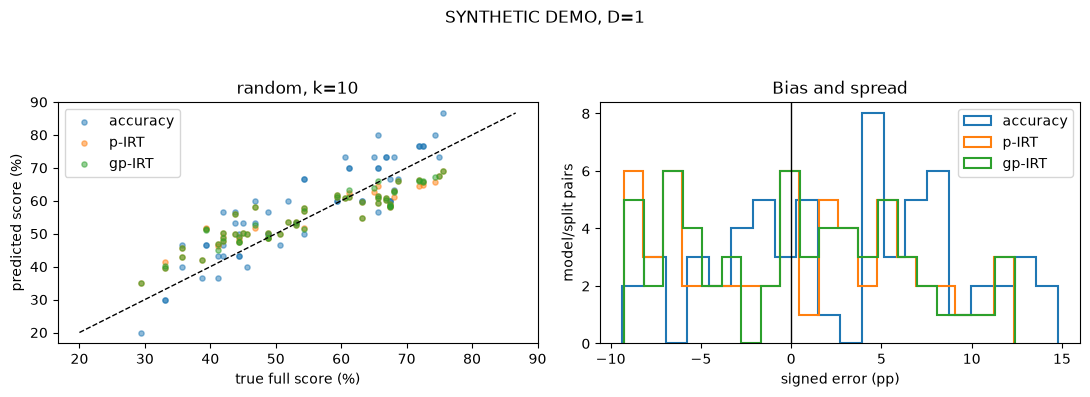

SYNTHETIC DEMO, D=2


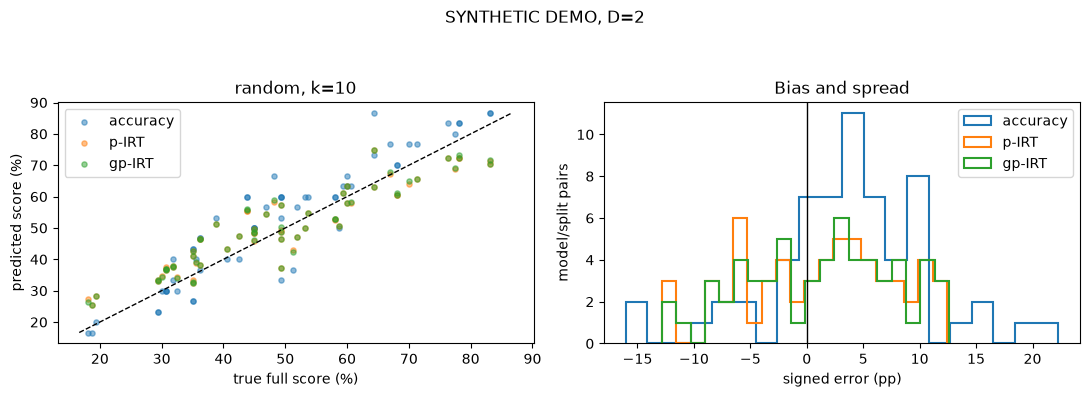

In [5]:
for label, records in datasets.items():
    print(label)
    fig = plot_predictions(records, K, selector="random")
    fig.suptitle(label)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()

## Which questions are selected?

1D: item success probability at the training mean against discrimination magnitude.
MIRT: first two loading coordinates (a projection when D>2).
Green points are one shared static design. Two coloured sets show adaptive choices for two
response rows. Axes have no fixed semantic interpretation across separately fitted models.

Saved CSVs alone do not contain item parameters or trajectories. In results mode set
`view_context` to the same frozen adapter that produced the run and `view_responses` to aligned
response rows. This section then uses that model without refitting it.

SYNTHETIC DEMO, D=1


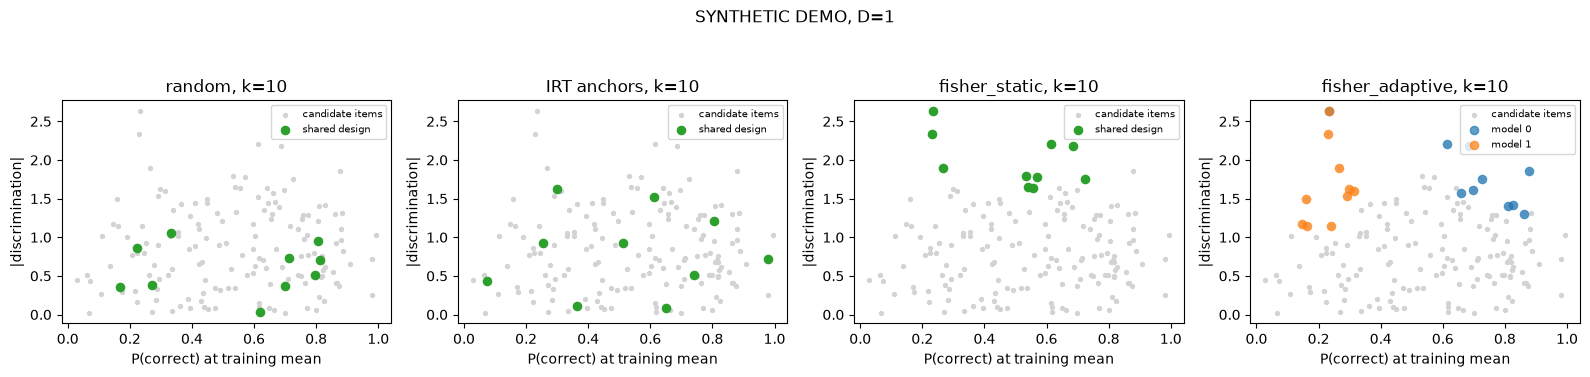

SYNTHETIC DEMO, D=2


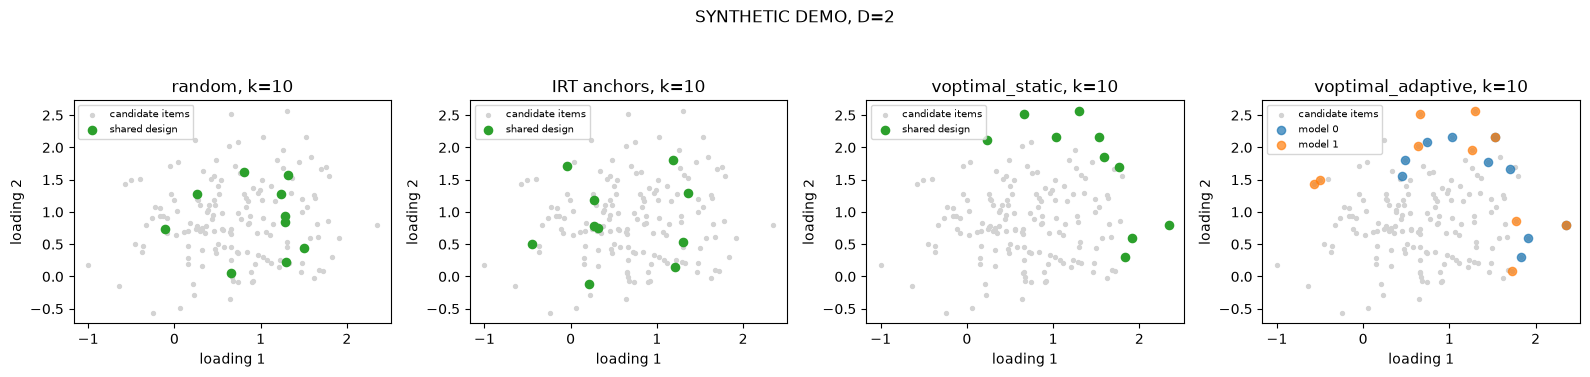

In [6]:
if not views:
    print("Supply view_context and view_responses to inspect real item choices.")
for label, (ctx, responses) in views.items():
    if responses is None:
        raise ValueError("Provide response rows aligned with view_context's item order")
    print(label)
    fig = plot_item_choices(ctx, responses, k=K, seed=SEED)
    fig.suptitle(label)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()

## Paired changes against random + gp-IRT

Negative ΔMAE favours the new method. Match the same targets before averaging seeds and
resampling paired split means. The research family splits overlap, so the interval reflects
split variability. Synthetic-demo intervals demonstrate the calculation only.

In [7]:
for label, records in datasets.items():
    paired = paired_comparison(records)
    headline = paired[(paired.k == K) & paired.method.str.endswith("+ gp-IRT")].copy()
    headline[["delta_mae", "ci_low", "ci_high"]] *= 100
    print(label)
    display(headline[["method", "delta_mae", "ci_low", "ci_high", "splits_won", "n_splits"]])

SYNTHETIC DEMO, D=1


,method,delta_mae,ci_low,ci_high,splits_won,n_splits
4,IRT anchors + gp-IRT,-0.104001,-0.897012,0.523733,1,3
13,fisher_adaptive + gp-IRT,-3.111082,-4.025969,-2.339656,3,3
22,fisher_static + gp-IRT,-2.648524,-2.904482,-2.202078,3,3
31,random + gp-IRT,0.000000,0.000000,0.000000,0,3


SYNTHETIC DEMO, D=2


,method,delta_mae,ci_low,ci_high,splits_won,n_splits
4,IRT anchors + gp-IRT,0.260463,-1.522848,1.748438,1,3
13,random + gp-IRT,0.000000,0.000000,0.000000,0,3
22,voptimal_adaptive + gp-IRT,-2.337688,-3.164033,-1.079496,3,3
31,voptimal_static + gp-IRT,-2.566210,-3.483560,-1.678303,3,3
